# Student Performance Indicator
### Life cycle of Machine Learning Project
        - Understanding the problem Statement
        - Data Collection
        - Data Checks to perform
        - Exploratory data analysis
        - Data Pre-Processing
        - Model Training
        - Choose best model

### 1) Problem Statement
* This Project understanding how the student performance(test score) is affected by other variables such as Gender, Ethnicity, Parental level of eduction etc.

### 2) Data Collection
* 


In [1]:
# Import Requirements of library
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
# Read the Data
df = pd.read_csv("data/stud.csv")
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [4]:
df.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [5]:
df.shape

(1000, 8)

In [6]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='object')

### Data set Information
- gender
- race_ethnicity
- parental_level_of_education
- lunch
- test_preparation_course
- math_score
- reading_score
- writing_score
### Data check to perform
- Missing Value
- Duplicate
- data type
- Number of unique value of each colmns
- statistics of data set
- check various categories present in the different categorical column


In [7]:
df.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [10]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### Exploring Data

In [11]:
print("Categories in gender variable : ", end=" ")
print(df['gender'].nunique(),df['gender'].unique())

print("Categories in race_ethnicity variable : ", end=" ")
print(df["race_ethnicity"].unique(),df["race_ethnicity"].nunique())

print("Categories in lunch variable : ", end=" ")
print(df["lunch"].unique(), df['lunch'].nunique())

print("Categories in test_preparation_course variable : ", end=" ")
print(df['test_preparation_course'].unique(),df['test_preparation_course'].nunique())

print("Categories in parental_level_of_education variable : ", end=" ")
print(df['parental_level_of_education'].unique(),df['parental_level_of_education'].nunique())


Categories in gender variable :  2 ['female' 'male']
Categories in race_ethnicity variable :  ['group B' 'group C' 'group A' 'group D' 'group E'] 5
Categories in lunch variable :  ['standard' 'free/reduced'] 2
Categories in test_preparation_course variable :  ['none' 'completed'] 2
Categories in parental_level_of_education variable :  ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school'] 6


In [13]:
# Define numerical and categorical columns
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Print columns
print(f"We have {len(numeric_features)} numerical features: {numeric_features}")
print(f"We have {len(categorical_features)} categorical features: {categorical_features}")

We have 3 numerical features: ['math_score', 'reading_score', 'writing_score']
We have 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


### Adding columns for  the total score

In [14]:
df['total score'] = df["math_score"]+df['reading_score']+df['writing_score']
df['avg score'] = df['total score']/3
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'avg score'],
      dtype='object')

In [18]:
reading_full = df[df['reading_score']==100]['avg score'].count()
writing_full = df[df["writing_score"]==100]['avg score'].count()
math_full = df[df['math_score']==100]['avg score'].count()

print(f"Number of the students with full marks in math :{math_full}")
print(f"Number of the students with full marks in writing :{writing_full}")
print(f"Number of the students with full marks in reading :{reading_full}")


Number of the students with full marks in math :7
Number of the students with full marks in writing :14
Number of the students with full marks in reading :17


In [22]:
reading_less_than_20 = df[df['reading_score']<=20]['avg score'].count()
writing_less_than_20 = df[df["writing_score"]<=20]['avg score'].count()
math_less_than_20 = df[df['math_score']<=20]['avg score'].count()

print(f"Number of the students with less than 20 marks in math :{math_less_than_20}")
print(f"Number of the students less than 20 marks in writing :{writing_less_than_20}")
print(f"Number of the students less than 20 marks in reading :{reading_less_than_20}")

Number of the students with less than 20 marks in math :4
Number of the students less than 20 marks in writing :3
Number of the students less than 20 marks in reading :1


### Visualization

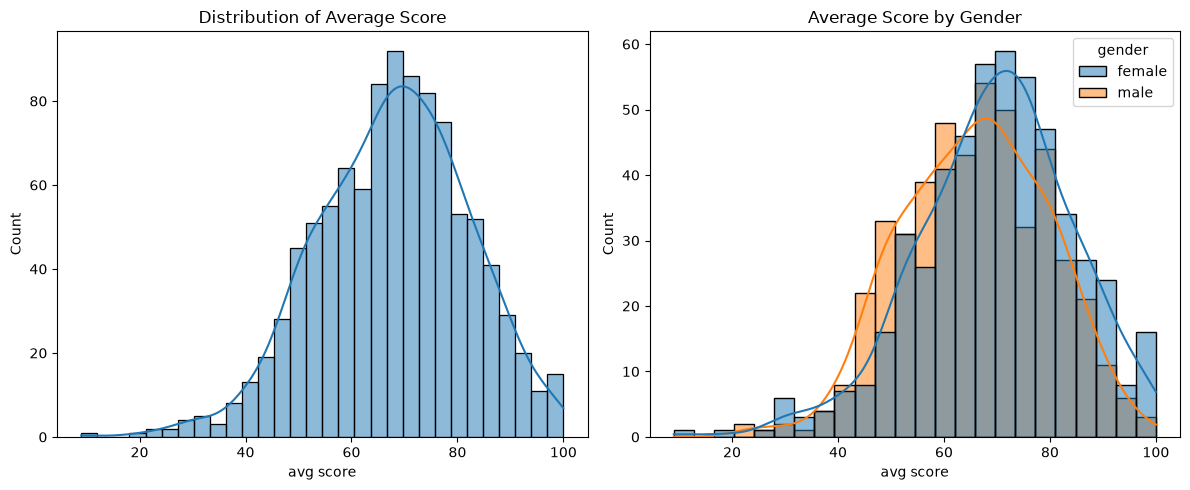

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Histogram + KDE
sns.histplot(data=df, x='avg score', bins=30, kde=True, ax=axs[0])
axs[0].set_title('Distribution of Average Score')

# Histogram + KDE by gender
sns.histplot(data=df, x='avg score', kde=True, hue='gender', ax=axs[1])
axs[1].set_title('Average Score by Gender')

plt.tight_layout()
plt.show()

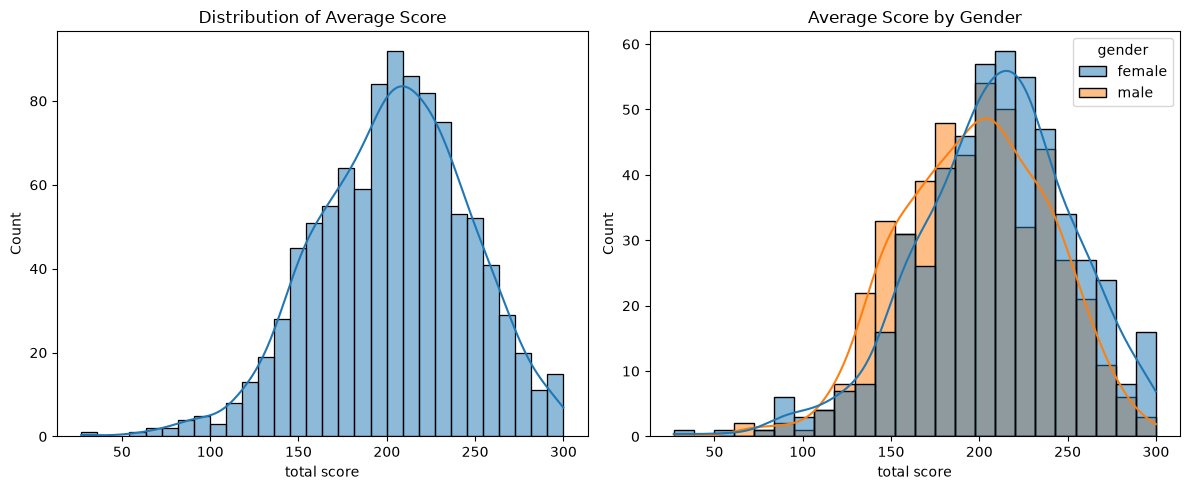

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Histogram + KDE
sns.histplot(data=df, x='total score', bins=30, kde=True, ax=axs[0])
axs[0].set_title('Distribution of Average Score')

# Histogram + KDE by gender
sns.histplot(data=df, x='total score', kde=True, hue='gender', ax=axs[1])
axs[1].set_title('Average Score by Gender')

plt.tight_layout()
plt.show()

In [28]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score', 'total score', 'avg score'],
      dtype='object')

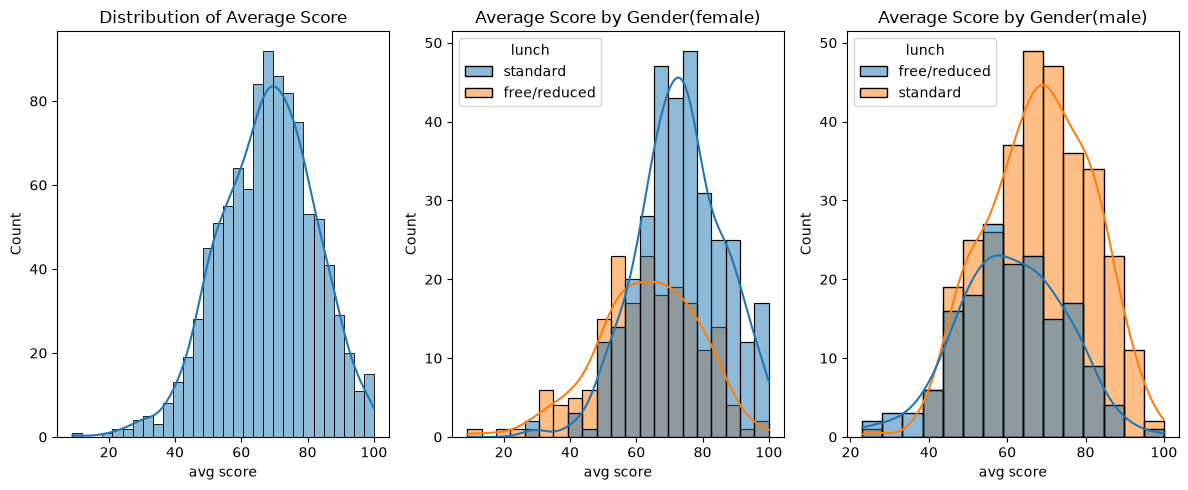

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(12, 5))

# Histogram + KDE
sns.histplot(data=df, x='avg score', bins=30, kde=True, ax=axs[0])
axs[0].set_title('Distribution of Average Score')

# Histogram + KDE by gender
sns.histplot(data=df[df.gender=='female'], x='avg score', kde=True, hue='lunch', ax=axs[1])
axs[1].set_title('Average Score by Gender(female)')

sns.histplot(data=df[df.gender=='male'], x='avg score', kde=True, hue='lunch', ax=axs[2])
axs[2].set_title('Average Score by Gender(male)')

plt.tight_layout()
plt.show()